# Reference-based SNR (RSNR) Comparison

다음 6가지 denoising 방법의 결과를 동일한 기준으로 비교한다.

1. Magnitude MP-PCA
2. Real / Imaginary Split MP-PCA
3. Real + Imaginary Combined MP-PCA
4. Direct Complex MP-PCA
5. Complex Wishart MP-PCA
6. Hybrid Multi-Echo MP-PCA

본 실험에서는 synthetic noise 추가 전 원본 magnitude 영상을 reference image로 사용한다. 각 noisy/denoised 영상이 reference image에 얼마나 가깝게 복원되었는지를 평가하기 위해 reference signal의 RMS와 reconstruction error의 RMS 비율을 이용한 Reference-based SNR(RSNR)을 계산한다.

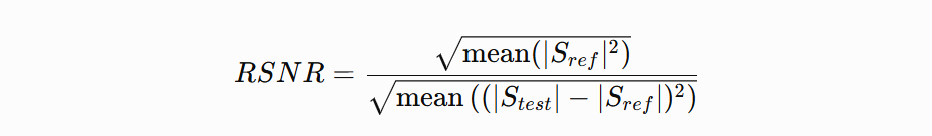

- 분자: reference image의 RMS signal
- 분모: test image와 reference image 차이의 RMSE
- RSNR이 클수록 reference image에 더 가깝게 복원된 것을 의미한다.
- 본 지표는 일반적인 배경-noise 기반 acquisition SNR과 구분하기 위해 RSNR로 표기한다.


In [2]:
import os
import glob
from pathlib import Path

import numpy as np
import scipy.io as sio
import pandas as pd
import matplotlib.pyplot as plt


### 1. 기본 설정


In [4]:
NOISE_LEVELS = [10, 30, 50]
N_ECHO = 6

DATA_DIR = Path("./data")
NOISY_DIR = DATA_DIR / "noisy_data"
DENOISED_DIR = DATA_DIR / "denoised"

ORIG_PATH = DATA_DIR / "meas_gre_dir1.mat"

print("Original :", ORIG_PATH)
print("Noisy dir:", NOISY_DIR)
print("Denoised :", DENOISED_DIR)


Original : data\meas_gre_dir1.mat
Noisy dir: data\noisy_data
Denoised : data\denoised


### 2. 원본 데이터 및 mask 불러오기


In [6]:
orig_mat = sio.loadmat(
    ORIG_PATH,
    simplify_cells=True
)

orig_complex = orig_mat["meas_gre"]
orig_mag = np.abs(orig_complex).astype(np.float32)

if "mask_brain" in orig_mat:
    mask = orig_mat["mask_brain"].astype(bool)
else:
    mask = np.abs(orig_complex[..., 0]) > 0

print("Original shape :", orig_complex.shape)
print("Original dtype :", orig_complex.dtype)
print("Mask shape     :", mask.shape)
print("Mask voxels    :", int(mask.sum()))


Original shape : (256, 224, 176, 6)
Original dtype : complex128
Mask shape     : (256, 224, 176)
Mask voxels    : 1433661


### 3. 파일 자동 탐색 함수


In [8]:
def find_one(patterns):
    """
    여러 glob pattern 중 처음 발견되는 파일 하나를 반환한다.
    """
    for pattern in patterns:
        matches = sorted(glob.glob(pattern))
        if matches:
            return Path(matches[0])

    raise FileNotFoundError(
        "파일을 찾지 못했습니다.\n"
        + "\n".join(patterns)
    )


def show_mat_keys(path):
    mat = sio.loadmat(
        path,
        simplify_cells=True
    )
    keys = [
        key for key in mat.keys()
        if not key.startswith("__")
    ]
    print(path)
    print("keys:", keys)
    return keys


### 4. Noisy magnitude 불러오기


In [10]:
def load_noisy_magnitude(noise_level):
    path = NOISY_DIR / f"noisy_meas_gre_dir1_{noise_level}.mat"

    mat = sio.loadmat(
        path,
        simplify_cells=True
    )

    noisy_real = mat["noisy_real"]
    noisy_imag = mat["noisy_imag"]

    noisy_complex = (
        noisy_real + 1j * noisy_imag
    )

    return np.abs(noisy_complex).astype(np.float32)


### 5. Denoising 결과 불러오기

저장 폴더명이나 `.mat` 파일명이 조금 달라도 찾을 수 있도록 여러 후보 pattern을 사용한다.


In [12]:
def load_magnitude_result(noise_level):
    path = find_one([
        str(DENOISED_DIR / "magnitude" / f"*{noise_level}*.mat"),
        str(DENOISED_DIR / f"*magnitude*{noise_level}*.mat"),
        str(DATA_DIR / "**" / f"*magnitude*{noise_level}*.mat"),
    ])

    mat = sio.loadmat(
        path,
        simplify_cells=True
    )

    candidates = [
        "denoised_magnitude",
        "deno_mag",
        "magnitude_denoised",
        "denoised"
    ]

    for key in candidates:
        if key in mat:
            arr = np.asarray(mat[key])

            # 혹시 complex로 저장되어 있다면 magnitude 변환
            if np.iscomplexobj(arr):
                arr = np.abs(arr)

            print("Magnitude      :", path, "->", key)
            return arr.astype(np.float32)

    raise KeyError(
        f"Magnitude 결과 변수명을 찾지 못했습니다. keys={list(mat.keys())}"
    )


def load_split_result(noise_level):
    path = find_one([
        str(DENOISED_DIR / "real_imag" / f"*{noise_level}*.mat"),
        str(DENOISED_DIR / "split" / f"*{noise_level}*.mat"),
        str(DENOISED_DIR / f"*real*imag*{noise_level}*.mat"),
        str(DATA_DIR / "**" / f"*real*imag*{noise_level}*.mat"),
    ])

    mat = sio.loadmat(
        path,
        simplify_cells=True
    )

    # complex 결과가 직접 저장된 경우
    for key in [
        "denoised_complex",
        "complex_denoised",
        "deno_complex"
    ]:
        if key in mat:
            print("Real/Imag Split:", path, "->", key)
            return np.abs(mat[key]).astype(np.float32)

    # real / imag 별도 저장
    real_keys = [
        "denoised_real",
        "real_denoised",
        "deno_real"
    ]

    imag_keys = [
        "denoised_imag",
        "imag_denoised",
        "deno_imag"
    ]

    real = None
    imag = None

    for key in real_keys:
        if key in mat:
            real = np.asarray(mat[key])
            break

    for key in imag_keys:
        if key in mat:
            imag = np.asarray(mat[key])
            break

    if real is not None and imag is not None:
        print("Real/Imag Split:", path, "-> real + imag")
        return np.abs(real + 1j * imag).astype(np.float32)

    raise KeyError(
        f"Split 결과 변수명을 찾지 못했습니다. keys={list(mat.keys())}"
    )


def load_combined_result(noise_level):
    path = find_one([
        str(DENOISED_DIR / "combined" / f"*{noise_level}*.mat"),
        str(DENOISED_DIR / "real_imag_combined" / f"*{noise_level}*.mat"),
        str(DENOISED_DIR / f"*combined*{noise_level}*.mat"),
        str(DATA_DIR / "**" / f"*combined*{noise_level}*.mat"),
    ])

    mat = sio.loadmat(
        path,
        simplify_cells=True
    )

    # 이미 complex로 저장되어 있으면 그대로 사용
    for key in [
        "denoised_complex",
        "complex_denoised",
        "deno_complex"
    ]:
        if key in mat:
            print("Combined       :", path, "->", key)
            return np.abs(mat[key]).astype(np.float32)

    # 12채널 결과가 저장된 경우
    for key in [
        "combined_denoised",
        "denoised_all",
        "denoised_combined"
    ]:
        if key in mat:
            den = np.asarray(mat[key])

            if den.shape[-1] != 2 * N_ECHO:
                raise ValueError(
                    f"Combined 결과의 마지막 축이 {den.shape[-1]}입니다. "
                    f"예상값은 {2*N_ECHO}입니다."
                )

            real = den[..., :N_ECHO]
            imag = den[..., N_ECHO:]

            print("Combined       :", path, "->", key)
            return np.abs(real + 1j * imag).astype(np.float32)

    raise KeyError(
        f"Combined 결과 변수명을 찾지 못했습니다. keys={list(mat.keys())}"
    )


def load_direct_complex_result(noise_level):
    path = find_one([
        str(DENOISED_DIR / "direct_complex" / f"*{noise_level}*.mat"),
        str(DENOISED_DIR / f"*direct*complex*{noise_level}*.mat"),
        str(DATA_DIR / "**" / f"*direct*complex*{noise_level}*.mat"),
    ])

    mat = sio.loadmat(
        path,
        simplify_cells=True
    )

    for key in [
        "deno_complex",
        "denoised_complex",
        "complex_denoised"
    ]:
        if key in mat:
            print("Direct Complex :", path, "->", key)
            return np.abs(mat[key]).astype(np.float32)

    raise KeyError(
        f"Direct Complex 결과 변수명을 찾지 못했습니다. keys={list(mat.keys())}"
    )


def load_complex_wishart_result(noise_level):
    path = find_one([
        str(DENOISED_DIR / "complex_wishart" / f"*{noise_level}*.mat"),
        str(DENOISED_DIR / f"*wishart*{noise_level}*.mat"),
        str(DATA_DIR / "**" / f"*wishart*{noise_level}*.mat"),
    ])

    mat = sio.loadmat(
        path,
        simplify_cells=True
    )

    for key in [
        "deno_complex",
        "denoised_complex",
        "complex_denoised",
        "denoised"
    ]:
        if key in mat:
            arr = np.asarray(mat[key])

            if np.iscomplexobj(arr):
                arr = np.abs(arr)

            print("Complex Wishart :", path, "->", key)
            return arr.astype(np.float32)

    raise KeyError(
        f"Complex Wishart 결과 변수명을 찾지 못했습니다. keys={list(mat.keys())}"
    )


def load_hybrid_result(noise_level):
    path = find_one([
        str(DENOISED_DIR / "hybrid_multi_echo" / f"*{noise_level}*.mat"),
        str(DENOISED_DIR / f"*hybrid*{noise_level}*.mat"),
        str(DATA_DIR / "**" / f"*hybrid*{noise_level}*.mat"),
    ])

    mat = sio.loadmat(
        path,
        simplify_cells=True
    )

    for key in [
        "deno_complex",
        "denoised_complex",
        "hybrid_denoised",
        "denoised"
    ]:
        if key in mat:
            arr = np.asarray(mat[key])

            if np.iscomplexobj(arr):
                arr = np.abs(arr)

            print("Hybrid MultiEcho:", path, "->", key)
            return arr.astype(np.float32)

    raise KeyError(
        f"Hybrid 결과 변수명을 찾지 못했습니다. keys={list(mat.keys())}"
    )


### 6. Reference-based SNR (RSNR) 계산 함수


In [14]:
def calculate_rsnr(
    reference_mag,
    test_mag,
    mask,
    echo
):
    ref = reference_mag[..., echo][mask].astype(np.float64)
    test = test_mag[..., echo][mask].astype(np.float64)

    signal_rms = np.sqrt(
        np.mean(ref ** 2)
    )

    error_rms = np.sqrt(
        np.mean((test - ref) ** 2)
    )

    rsnr = signal_rms / (
        error_rms + 1e-12
    )

    return float(rsnr)


### 7. 전체 방법 RSNR 계산


In [16]:
METHOD_LOADERS = {
    "Magnitude": load_magnitude_result,
    "Real_Imag": load_split_result,
    "Combined": load_combined_result,
    "Direct_Complex": load_direct_complex_result,
    "Complex_Wishart": load_complex_wishart_result,
    "Hybrid_Multi_Echo": load_hybrid_result
}

results = []

for noise_level in NOISE_LEVELS:

    print("\n" + "=" * 70)
    print(f"Noise level = {noise_level}%")
    print("=" * 70)

    # ----------------------------
    # Noisy baseline
    # ----------------------------
    noisy_mag = load_noisy_magnitude(
        noise_level
    )

    for echo in range(N_ECHO):
        rsnr = calculate_rsnr(
            orig_mag,
            noisy_mag,
            mask,
            echo
        )

        results.append({
            "Noise": noise_level,
            "Echo": echo,
            "Method": "Noisy",
            "RSNR": rsnr
        })

    # ----------------------------
    # Denoising methods
    # ----------------------------
    for method, loader in METHOD_LOADERS.items():

        den_mag = loader(
            noise_level
        )

        if den_mag.shape != orig_mag.shape:
            raise ValueError(
                f"{method} shape mismatch: "
                f"{den_mag.shape} != {orig_mag.shape}"
            )

        for echo in range(N_ECHO):

            rsnr = calculate_rsnr(
                orig_mag,
                den_mag,
                mask,
                echo
            )

            results.append({
                "Noise": noise_level,
                "Echo": echo,
                "Method": method,
                "RSNR": rsnr
            })

    print("완료")



Noise level = 10%
Magnitude      : data\denoised\magnitude\denoised_magnitude_10_r2.mat -> deno_mag
Real/Imag Split: data\denoised\real_imag\denoised_real_imag_10_r2.mat -> deno_complex
Combined       : data\denoised\real_imag_combined\denoised_real_imag_combined_10_r2.mat -> deno_complex
Direct Complex : data\denoised\direct_complex\denoised_direct_complex_10_r2.mat -> deno_complex
Complex Wishart : data\denoised\complex_wishart\denoised_complex_wishart_10_r2_a0.99.mat -> denoised_complex
Hybrid MultiEcho: data\denoised\hybrid_multi_echo\denoised_hybrid_multi_echo_10_r2.mat -> denoised_complex
완료

Noise level = 30%
Magnitude      : data\denoised\magnitude\denoised_magnitude_30_r2.mat -> deno_mag
Real/Imag Split: data\denoised\real_imag\denoised_real_imag_30_r2.mat -> deno_complex
Combined       : data\denoised\real_imag_combined\denoised_real_imag_combined_30_r2.mat -> deno_complex
Direct Complex : data\denoised\direct_complex\denoised_direct_complex_30_r2.mat -> deno_complex
Complex

### 8. Echo별 RSNR 표


In [18]:
df_rsnr = pd.DataFrame(results)

rsnr_table = df_rsnr.pivot_table(
    index=["Noise", "Echo"],
    columns="Method",
    values="RSNR"
)

rsnr_table.round(4)


Method      Combined  Complex_Wishart  Direct_Complex  Hybrid_Multi_Echo  \
Noise Echo                                                                 
10    0      21.4001          20.5349         20.5005            15.2240   
      1      22.3835          21.3519         21.3229            17.5666   
      2      20.9691          19.8860         19.8722            16.9896   
      3      18.9829          18.0208         18.0232            15.8991   
      4      16.4991          15.6592         15.6644            13.4918   
      5      13.2703          12.5623         12.5417            10.0456   
30    0      10.8933          10.1939         10.1114             9.6315   
      1      11.0687          10.0707          9.9745             9.3982   
      2      10.3720           9.2585          9.1474             8.4748   
      3       9.2887           8.1700          8.0577             7.4459   
      4       8.0090           7.0086          6.9049             6.4664   
      5       6.8587           6.0206          5.9283             5.5047   
50    0       8.2945           7.9287          7.8461             7.1610   
      1       8.0477           7.4181          7.3244             6.4906   
      2       7.4354           6.7382          6.6348             5.6877   
      3       6.6912           6.0179          5.9035             4.9926   
      4       5.9419           5.3406          5.2266             4.4356   
      5       5.3433           4.8219          4.7141             3.9382   

Method      Magnitude    Noisy  Real_Imag  
Noise Echo                                 
10    0       20.5581  13.4332    20.2511  
      1       21.8106  12.2827    20.2101  
      2       20.4357  11.2236    18.5355  
      3       18.3737  10.2621    16.6932  
      4       16.1359   9.3913    14.6782  
      5       13.4798   8.5962    11.8729  
30    0        9.4902   4.4805     9.9238  
      1        9.3456   4.0939     9.5192  
      2        8.6505   3.7445     8.6880  
      3        7.7582   3.4269     7.7839  
      4        6.8296   3.1397     6.8332  
      5        5.9349   2.8753     5.8697  
50    0        5.8348   2.7147     7.5572  
      1        5.3669   2.4837     7.0503  
      2        4.7980   2.2733     6.3981  
      3        4.2223   2.0797     5.7872  
      4        3.6856   1.9038     5.1929  
      5        3.2016   1.7385     4.6744

### 9. 평균 RSNR 비교


In [20]:
mean_rsnr = (
    df_rsnr
    .groupby(
        ["Noise", "Method"],
        as_index=False
    )["RSNR"]
    .mean()
)

mean_rsnr_table = mean_rsnr.pivot(
    index="Noise",
    columns="Method",
    values="RSNR"
)

mean_rsnr_table.round(4)


Method,Combined,Complex_Wishart,Direct_Complex,Hybrid_Multi_Echo,Magnitude,Noisy,Real_Imag
Noise,,,,,,,
10,18.9175,18.0025,17.9875,14.8694,18.4656,10.8648,17.0402
30,9.4151,8.4537,8.3540,7.8203,8.0015,3.6268,8.1030
50,6.9590,6.3776,6.2749,5.4509,4.5182,2.1989,6.1100


### 10. RSNR 향상률 계산

Noisy 대비 각 denoising 방법의 RSNR 향상률을 계산한다.

\[
Improvement(\%) =
\frac{RSNR_{denoised}-RSNR_{noisy}}{RSNR_{noisy}} \times 100
\]


In [22]:
noisy_ref = (
    df_rsnr[
        df_rsnr["Method"] == "Noisy"
    ][["Noise", "Echo", "RSNR"]]
    .rename(
        columns={"RSNR": "Noisy_RSNR"}
    )
)

df_improvement = (
    df_rsnr[
        df_rsnr["Method"] != "Noisy"
    ]
    .merge(
        noisy_ref,
        on=["Noise", "Echo"],
        how="left"
    )
)

df_improvement["RSNR_Improvement_%"] = (
    (
        df_improvement["RSNR"]
        - df_improvement["Noisy_RSNR"]
    )
    / df_improvement["Noisy_RSNR"]
    * 100
)

improvement_table = df_improvement.pivot_table(
    index=["Noise", "Echo"],
    columns="Method",
    values="RSNR_Improvement_%"
)

improvement_table.round(2)


Method      Combined  Complex_Wishart  Direct_Complex  Hybrid_Multi_Echo  \
Noise Echo                                                                 
10    0        59.31            52.87           52.61              13.33   
      1        82.24            73.84           73.60              43.02   
      2        86.83            77.18           77.06              51.37   
      3        84.98            75.61           75.63              54.93   
      4        75.69            66.74           66.80              43.66   
      5        54.37            46.14           45.90              16.86   
30    0       143.13           127.52          125.67             114.96   
      1       170.37           146.00          143.65             129.57   
      2       176.99           147.25          144.29             126.33   
      3       171.05           138.41          135.13             117.27   
      4       155.09           123.23          119.92             105.96   
      5       138.54           109.39          106.18              91.45   
50    0       205.54           192.07          189.02             163.79   
      1       224.02           198.68          194.90             161.33   
      2       227.08           196.41          191.86             150.20   
      3       221.74           189.36          183.86             140.06   
      4       212.11           180.53          174.54             132.99   
      5       207.34           177.35          171.15             126.52   

Method      Magnitude  Real_Imag  
Noise Echo                        
10    0         53.04      50.75  
      1         77.57      64.54  
      2         82.08      65.15  
      3         79.04      62.67  
      4         71.82      56.30  
      5         56.81      38.12  
30    0        111.81     121.49  
      1        128.28     132.52  
      2        131.02     132.02  
      3        126.39     127.14  
      4        117.53     117.64  
      5        106.41     104.14  
50    0        114.93     178.38  
      1        116.09     183.86  
      2        111.06     181.45  
      3        103.03     178.27  
      4         93.59     172.77  
      5         84.16     168.87

### 11. Noise level별 Echo-RSNR 그래프


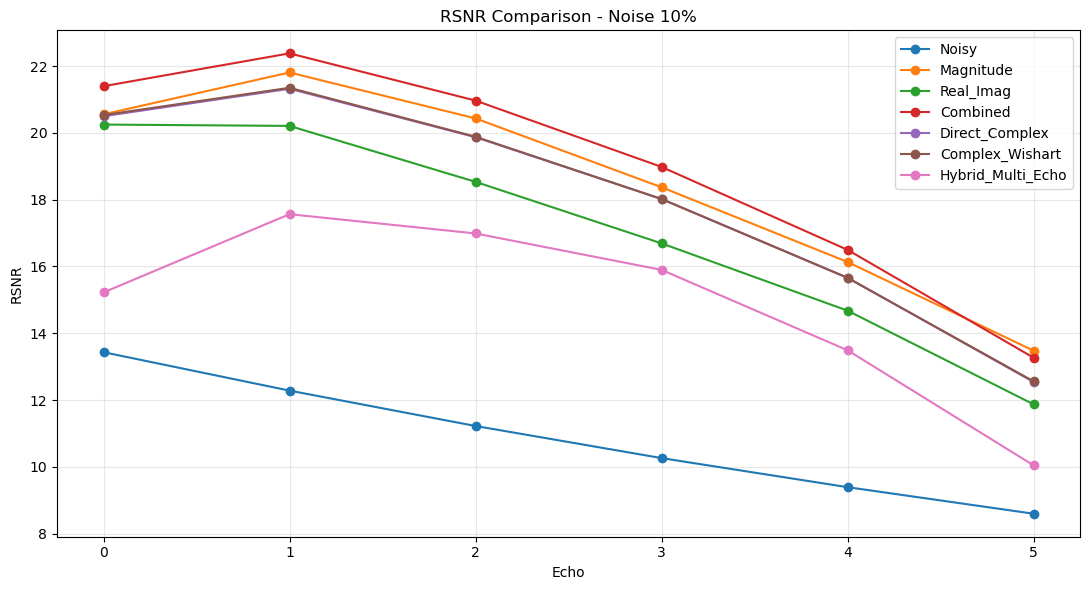

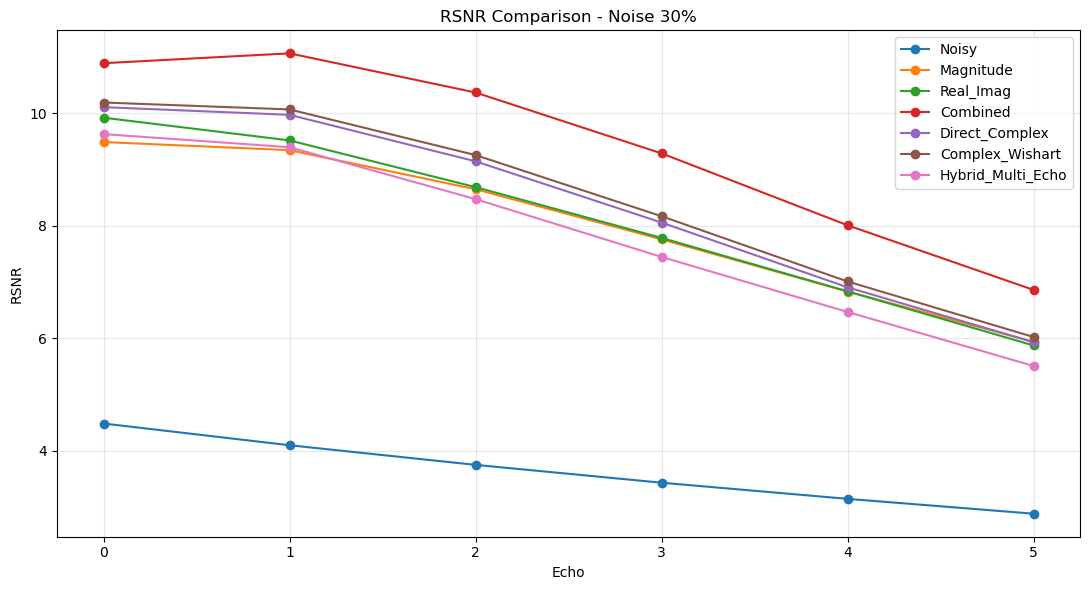

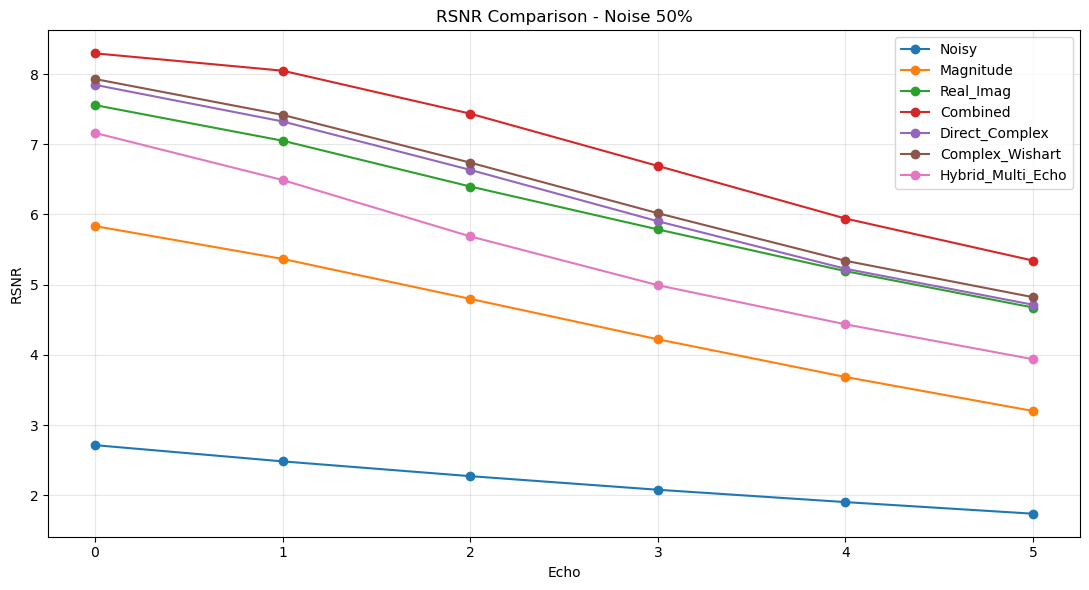

In [24]:
METHOD_ORDER = [
    "Noisy",
    "Magnitude",
    "Real_Imag",
    "Combined",
    "Direct_Complex",
    "Complex_Wishart",
    "Hybrid_Multi_Echo"
]

for noise_level in NOISE_LEVELS:

    temp = df_rsnr[
        df_rsnr["Noise"] == noise_level
    ]

    plt.figure(
        figsize=(11, 6)
    )

    for method in METHOD_ORDER:

        sub = temp[
            temp["Method"] == method
        ].sort_values("Echo")

        plt.plot(
            sub["Echo"],
            sub["RSNR"],
            marker="o",
            label=method
        )

    plt.xlabel("Echo")
    plt.ylabel("RSNR")
    plt.title(
        f"RSNR Comparison - Noise {noise_level}%"
    )

    plt.xticks(range(N_ECHO))
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


### 12. 평균 RSNR 막대그래프


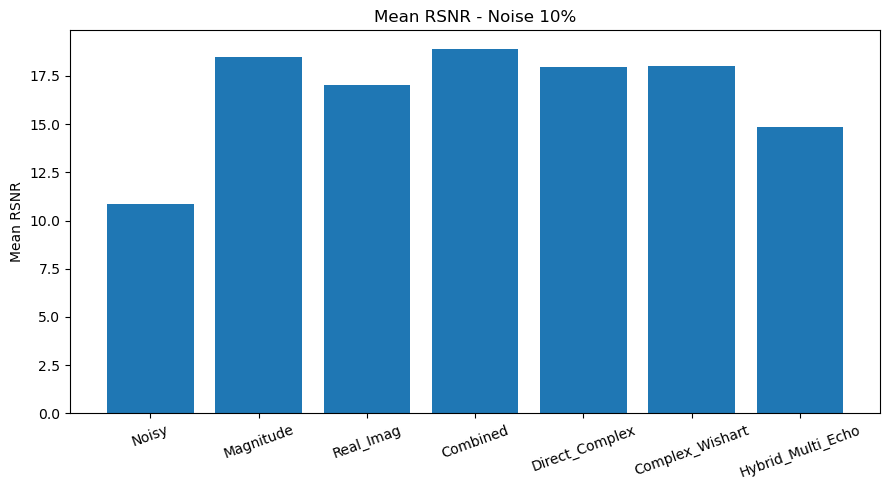

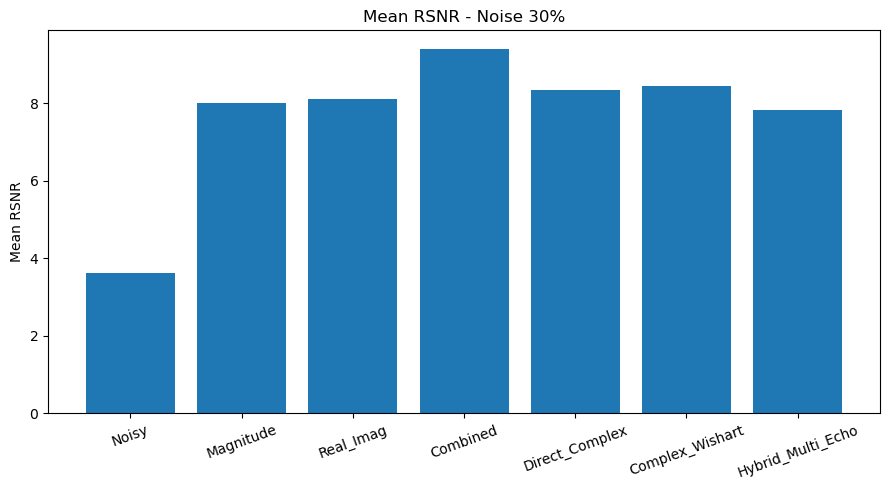

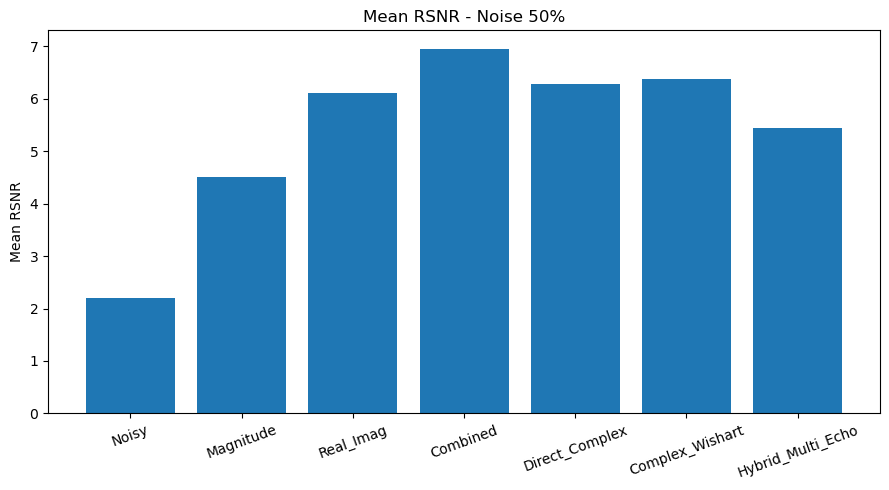

In [26]:
for noise_level in NOISE_LEVELS:

    temp = mean_rsnr[
        mean_rsnr["Noise"] == noise_level
    ].copy()

    temp["Method"] = pd.Categorical(
        temp["Method"],
        categories=METHOD_ORDER,
        ordered=True
    )

    temp = temp.sort_values(
        "Method"
    )

    plt.figure(
        figsize=(9, 5)
    )

    plt.bar(
        temp["Method"].astype(str),
        temp["RSNR"]
    )

    plt.ylabel("Mean RSNR")
    plt.title(
        f"Mean RSNR - Noise {noise_level}%"
    )

    plt.xticks(
        rotation=20
    )

    plt.tight_layout()
    plt.show()


### 13. 영상 비교 시각화

동일한 Echo와 Slice에서 다음 영상을 같은 display range로 비교한다.

- Original
- Noisy
- Magnitude MP-PCA
- Real / Imaginary Split
- Real + Imaginary Combined
- Direct Complex MP-PCA

`VIS_ECHO`와 `VIS_SLICE`를 변경하면 원하는 위치를 확인할 수 있다.


In [28]:
VIS_ECHO = 0
VIS_SLICE = orig_mag.shape[2] // 2

print("Visualization Echo :", VIS_ECHO)
print("Visualization Slice:", VIS_SLICE)


Visualization Echo : 0
Visualization Slice: 88


Magnitude      : data\denoised\magnitude\denoised_magnitude_10_r2.mat -> deno_mag
Real/Imag Split: data\denoised\real_imag\denoised_real_imag_10_r2.mat -> deno_complex
Combined       : data\denoised\real_imag_combined\denoised_real_imag_combined_10_r2.mat -> deno_complex
Direct Complex : data\denoised\direct_complex\denoised_direct_complex_10_r2.mat -> deno_complex
Complex Wishart : data\denoised\complex_wishart\denoised_complex_wishart_10_r2_a0.99.mat -> denoised_complex
Hybrid MultiEcho: data\denoised\hybrid_multi_echo\denoised_hybrid_multi_echo_10_r2.mat -> denoised_complex


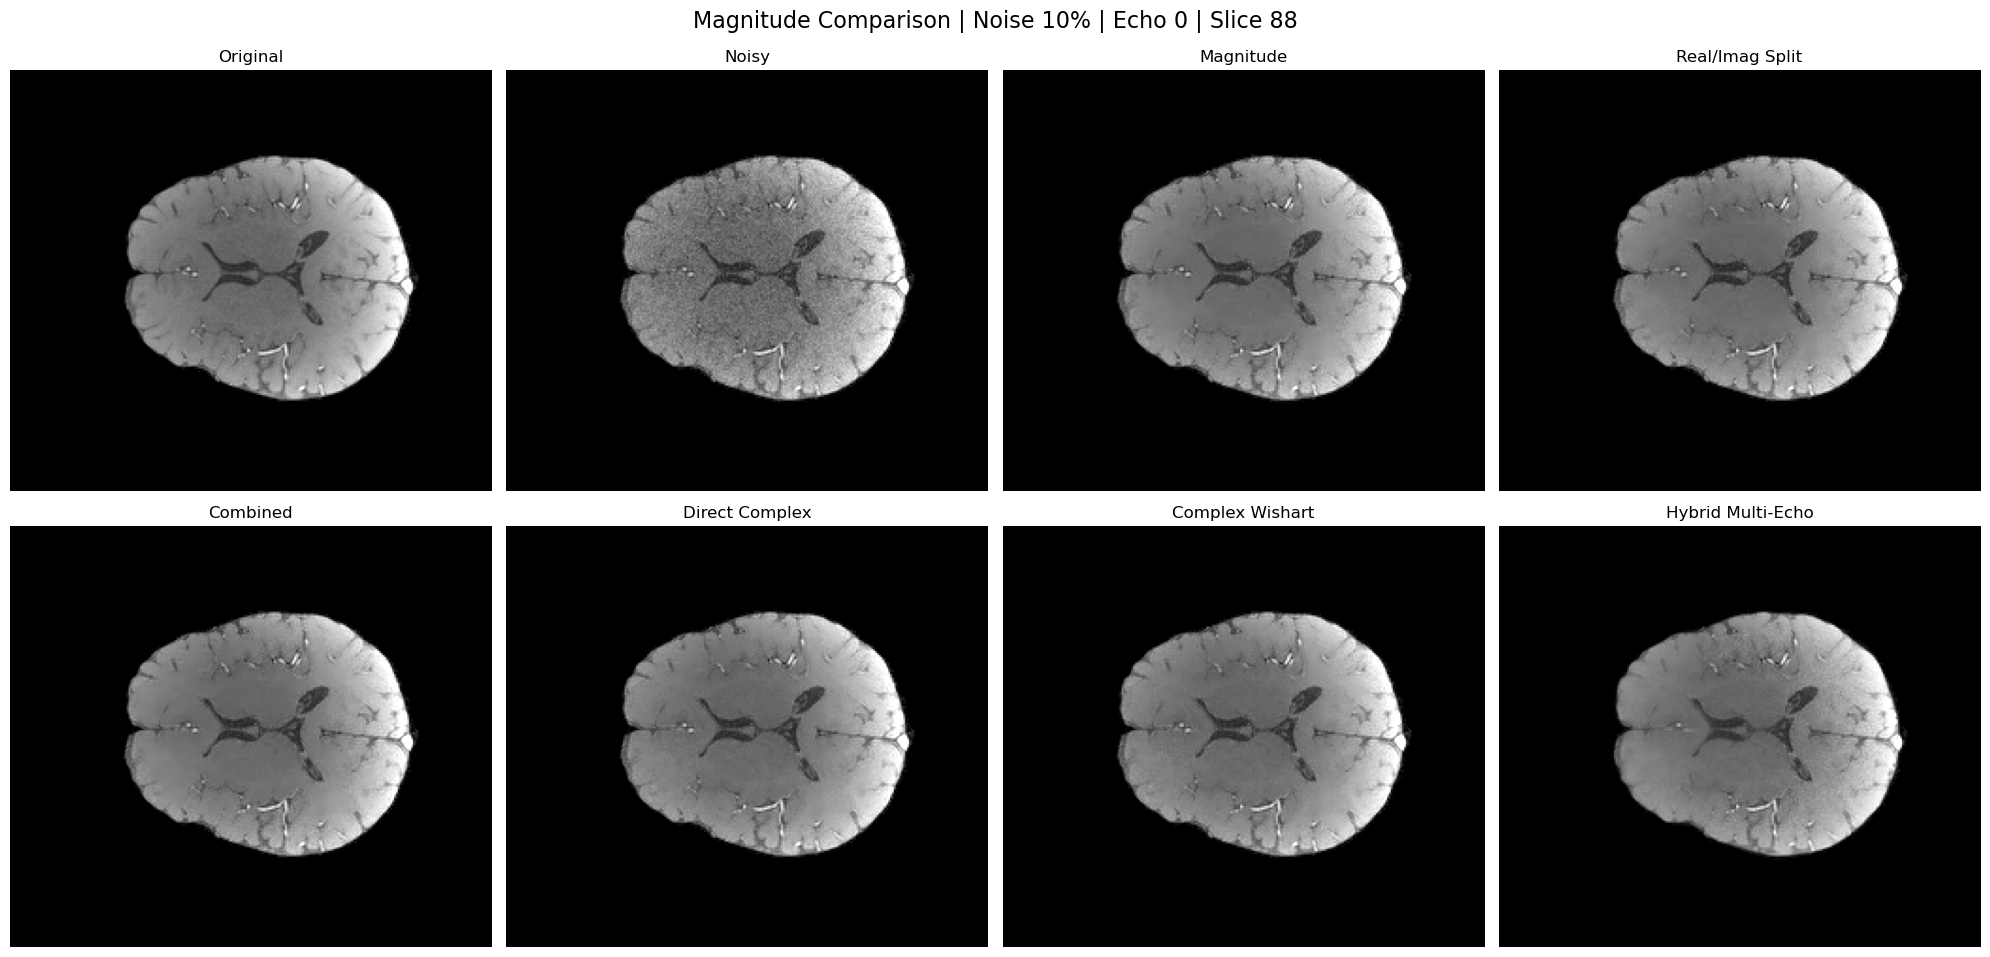

Magnitude      : data\denoised\magnitude\denoised_magnitude_30_r2.mat -> deno_mag
Real/Imag Split: data\denoised\real_imag\denoised_real_imag_30_r2.mat -> deno_complex
Combined       : data\denoised\real_imag_combined\denoised_real_imag_combined_30_r2.mat -> deno_complex
Direct Complex : data\denoised\direct_complex\denoised_direct_complex_30_r2.mat -> deno_complex
Complex Wishart : data\denoised\complex_wishart\denoised_complex_wishart_30_r2_a0.99.mat -> denoised_complex
Hybrid MultiEcho: data\denoised\hybrid_multi_echo\denoised_hybrid_multi_echo_30_r2.mat -> denoised_complex


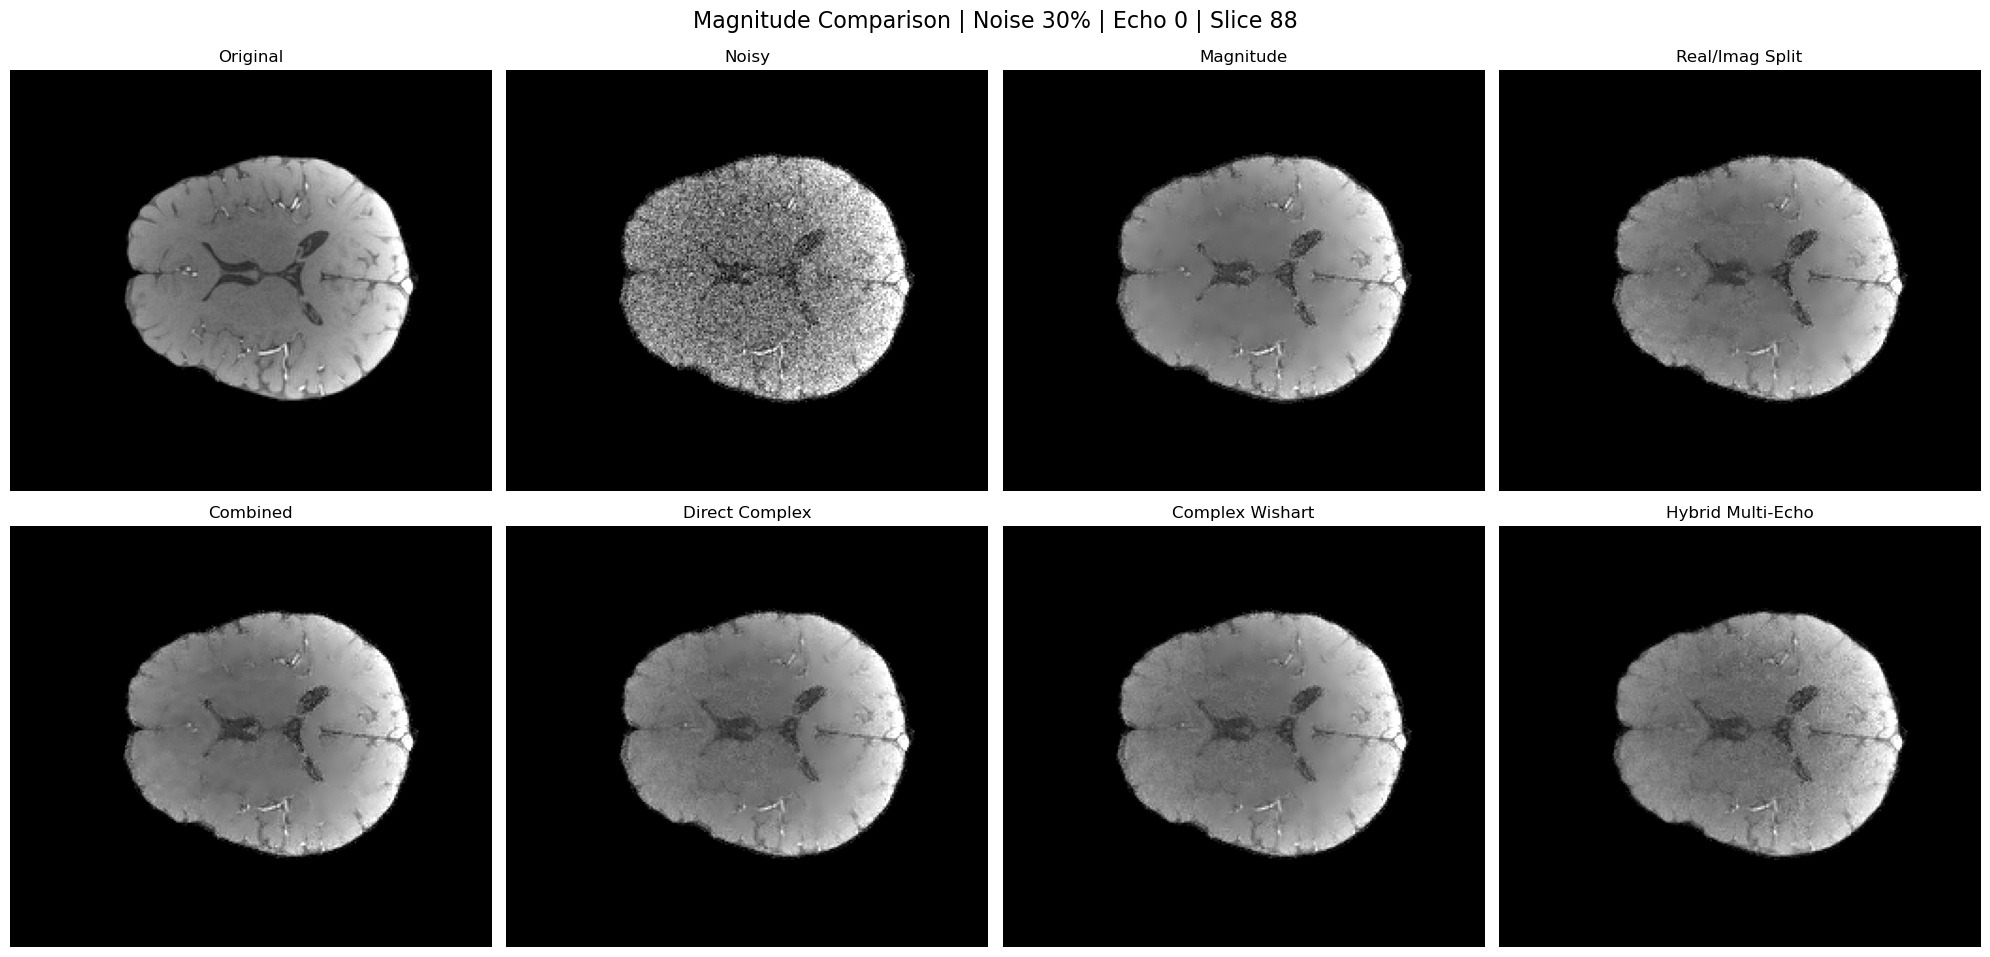

Magnitude      : data\denoised\magnitude\denoised_magnitude_50_r2.mat -> deno_mag
Real/Imag Split: data\denoised\real_imag\denoised_real_imag_50_r2.mat -> deno_complex
Combined       : data\denoised\real_imag_combined\denoised_real_imag_combined_50_r2.mat -> deno_complex
Direct Complex : data\denoised\direct_complex\denoised_direct_complex_50_r2.mat -> deno_complex
Complex Wishart : data\denoised\complex_wishart\denoised_complex_wishart_50_r2_a0.99.mat -> denoised_complex
Hybrid MultiEcho: data\denoised\hybrid_multi_echo\denoised_hybrid_multi_echo_50_r2.mat -> denoised_complex


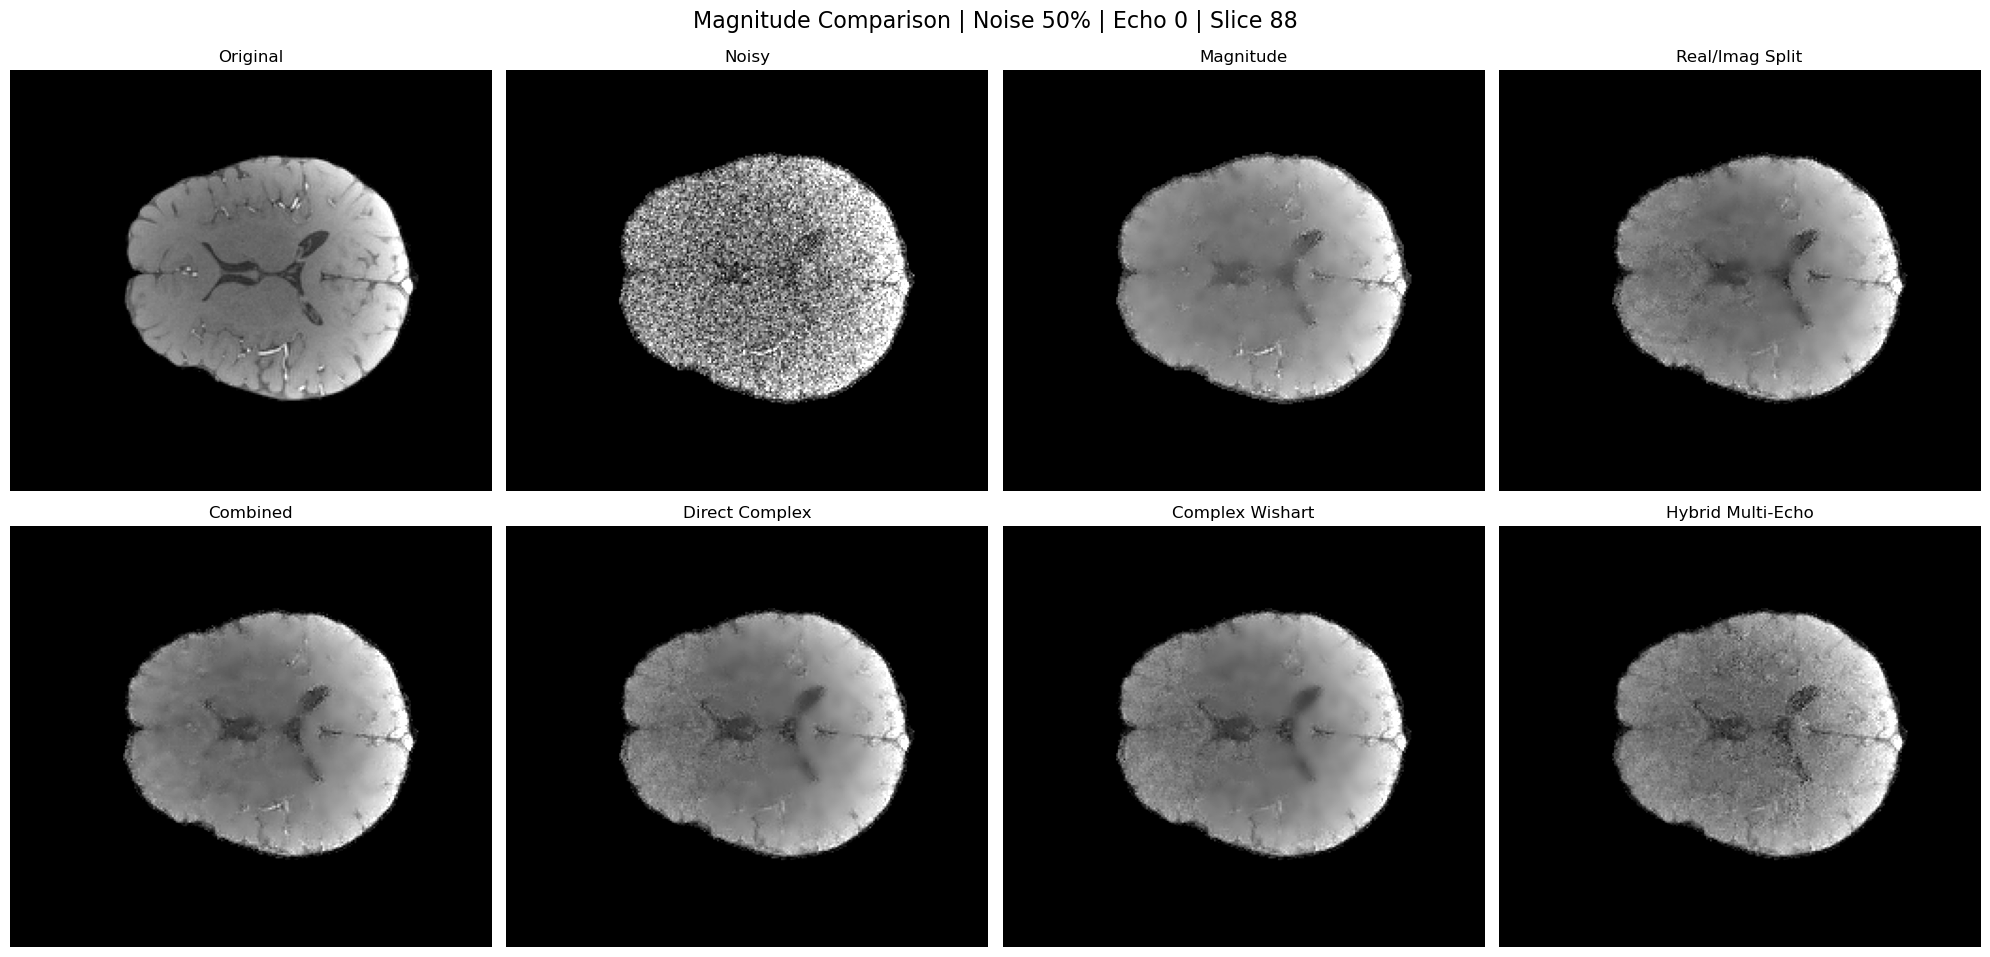

In [29]:
# 동일한 display range 사용
original_slice = orig_mag[:, :, VIS_SLICE, VIS_ECHO]

vmin = np.percentile(
    original_slice[mask[:, :, VIS_SLICE]],
    1
)

vmax = np.percentile(
    original_slice[mask[:, :, VIS_SLICE]],
    99
)

for noise_level in NOISE_LEVELS:

    noisy_mag = load_noisy_magnitude(noise_level)

    method_images = {
        "Original": orig_mag,
        "Noisy": noisy_mag,
        "Magnitude": load_magnitude_result(noise_level),
        "Real/Imag Split": load_split_result(noise_level),
        "Combined": load_combined_result(noise_level),
        "Direct Complex": load_direct_complex_result(noise_level),
        "Complex Wishart": load_complex_wishart_result(noise_level),
        "Hybrid Multi-Echo": load_hybrid_result(noise_level),
    }

    fig, axes = plt.subplots(
        2,
        4,
        figsize=(20, 10)
    )

    axes = axes.ravel()

    for ax, (name, image) in zip(
        axes,
        method_images.items()
    ):
        img = image[
            :,
            :,
            VIS_SLICE,
            VIS_ECHO
        ]

        ax.imshow(
            img.T,
            cmap="gray",
            origin="lower",
            vmin=vmin,
            vmax=vmax
        )

        ax.set_title(name)
        ax.axis("off")

    for ax in axes[len(method_images):]:
        ax.axis("off")

    fig.suptitle(
        f"Magnitude Comparison | Noise {noise_level}% | "
        f"Echo {VIS_ECHO} | Slice {VIS_SLICE}",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()


### 14. Difference Map 비교

각 denoising 결과에서 원본 magnitude를 뺀 차이를 비교한다.

Difference가 0에 가까울수록 원본과 유사하며, 동일한 범위를 사용하여 방법 간 차이를 비교한다.


Magnitude      : data\denoised\magnitude\denoised_magnitude_10_r2.mat -> deno_mag
Real/Imag Split: data\denoised\real_imag\denoised_real_imag_10_r2.mat -> deno_complex
Combined       : data\denoised\real_imag_combined\denoised_real_imag_combined_10_r2.mat -> deno_complex
Direct Complex : data\denoised\direct_complex\denoised_direct_complex_10_r2.mat -> deno_complex
Complex Wishart : data\denoised\complex_wishart\denoised_complex_wishart_10_r2_a0.99.mat -> denoised_complex
Hybrid MultiEcho: data\denoised\hybrid_multi_echo\denoised_hybrid_multi_echo_10_r2.mat -> denoised_complex


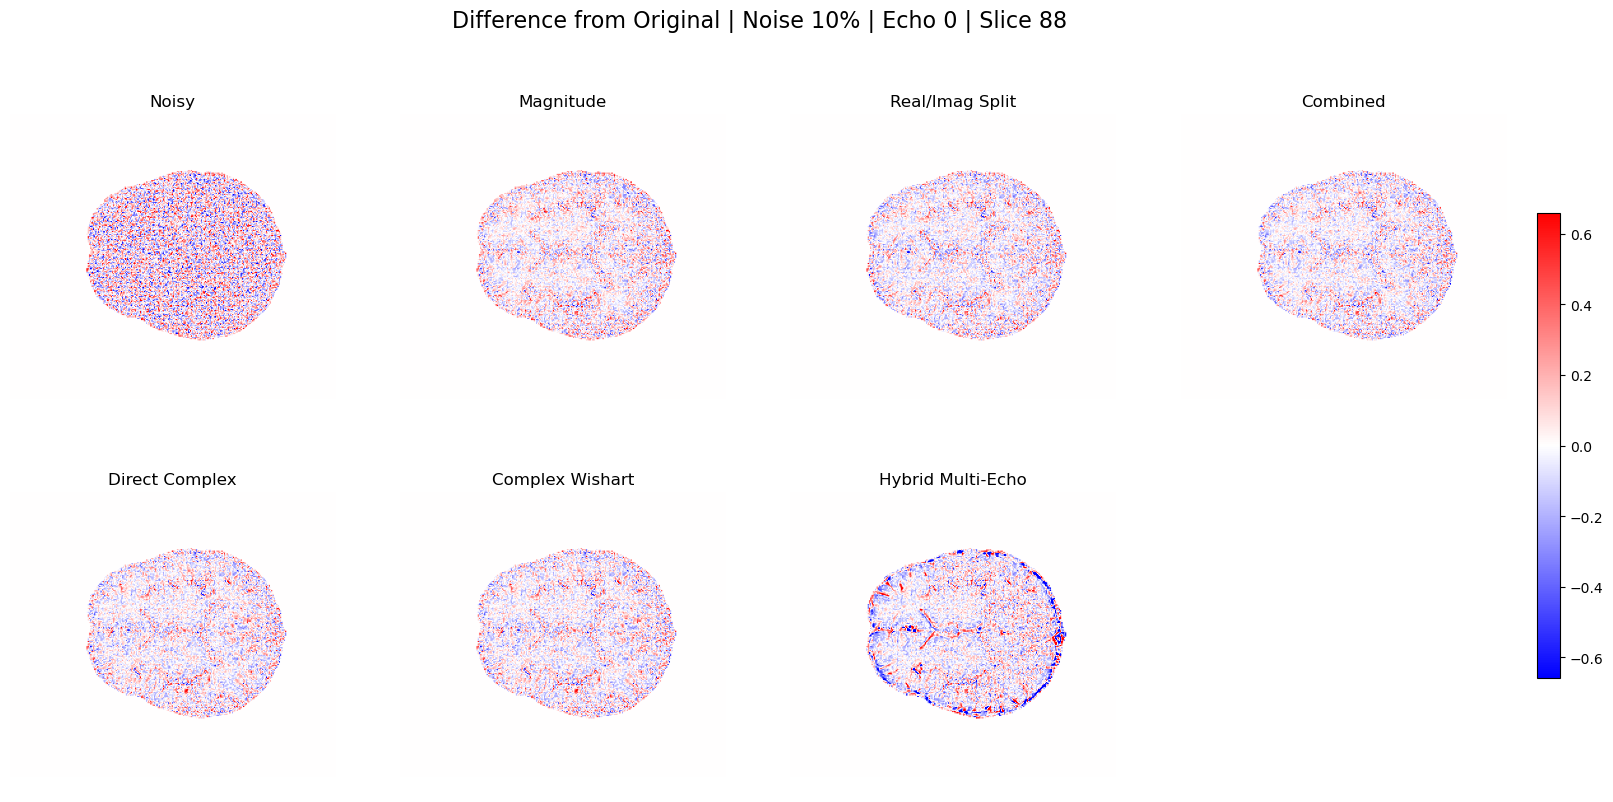

Magnitude      : data\denoised\magnitude\denoised_magnitude_30_r2.mat -> deno_mag
Real/Imag Split: data\denoised\real_imag\denoised_real_imag_30_r2.mat -> deno_complex
Combined       : data\denoised\real_imag_combined\denoised_real_imag_combined_30_r2.mat -> deno_complex
Direct Complex : data\denoised\direct_complex\denoised_direct_complex_30_r2.mat -> deno_complex
Complex Wishart : data\denoised\complex_wishart\denoised_complex_wishart_30_r2_a0.99.mat -> denoised_complex
Hybrid MultiEcho: data\denoised\hybrid_multi_echo\denoised_hybrid_multi_echo_30_r2.mat -> denoised_complex


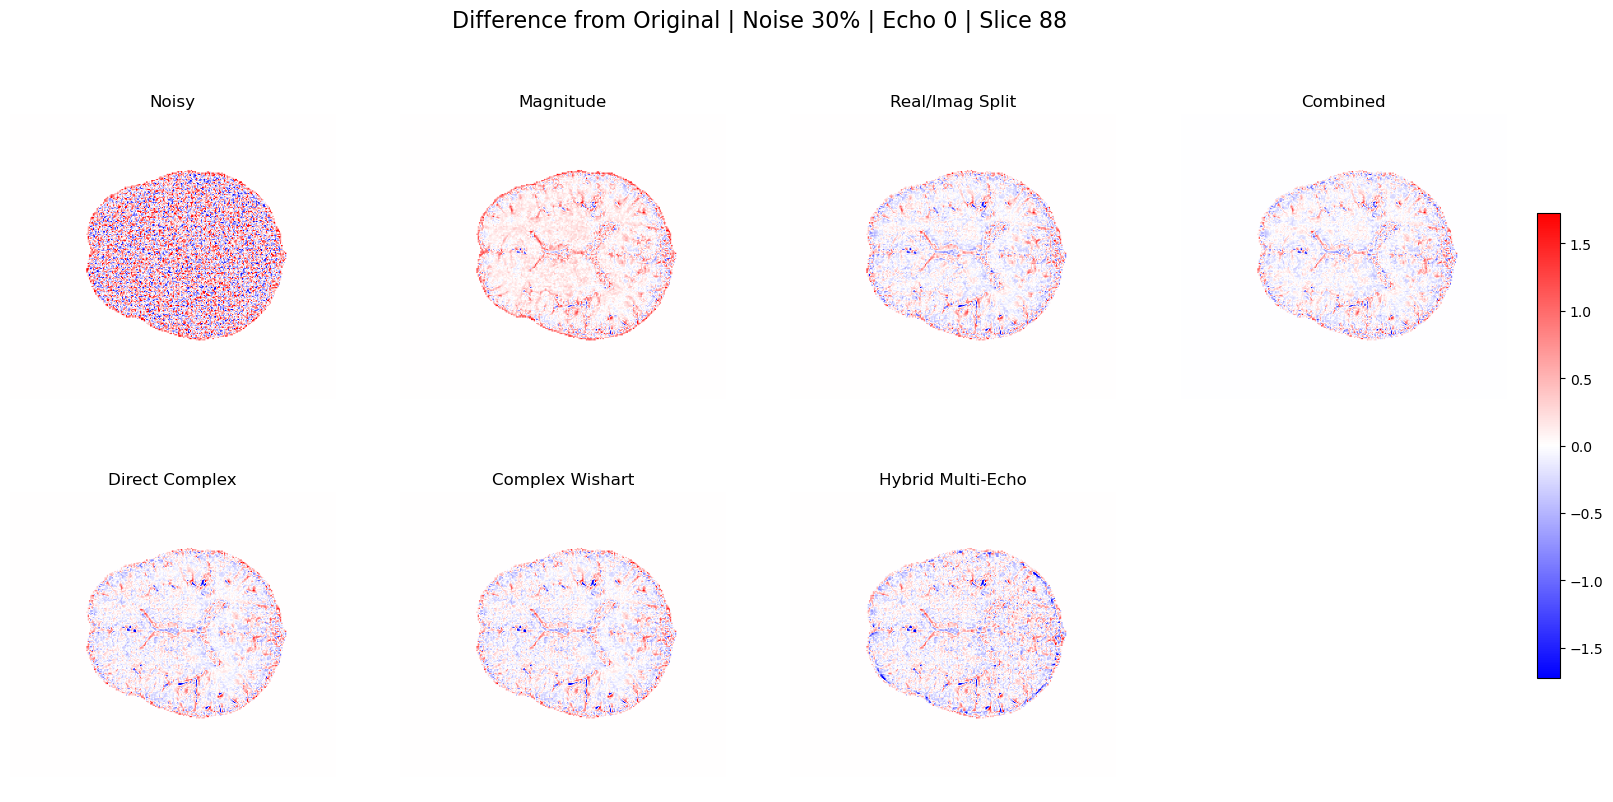

Magnitude      : data\denoised\magnitude\denoised_magnitude_50_r2.mat -> deno_mag
Real/Imag Split: data\denoised\real_imag\denoised_real_imag_50_r2.mat -> deno_complex
Combined       : data\denoised\real_imag_combined\denoised_real_imag_combined_50_r2.mat -> deno_complex
Direct Complex : data\denoised\direct_complex\denoised_direct_complex_50_r2.mat -> deno_complex
Complex Wishart : data\denoised\complex_wishart\denoised_complex_wishart_50_r2_a0.99.mat -> denoised_complex
Hybrid MultiEcho: data\denoised\hybrid_multi_echo\denoised_hybrid_multi_echo_50_r2.mat -> denoised_complex


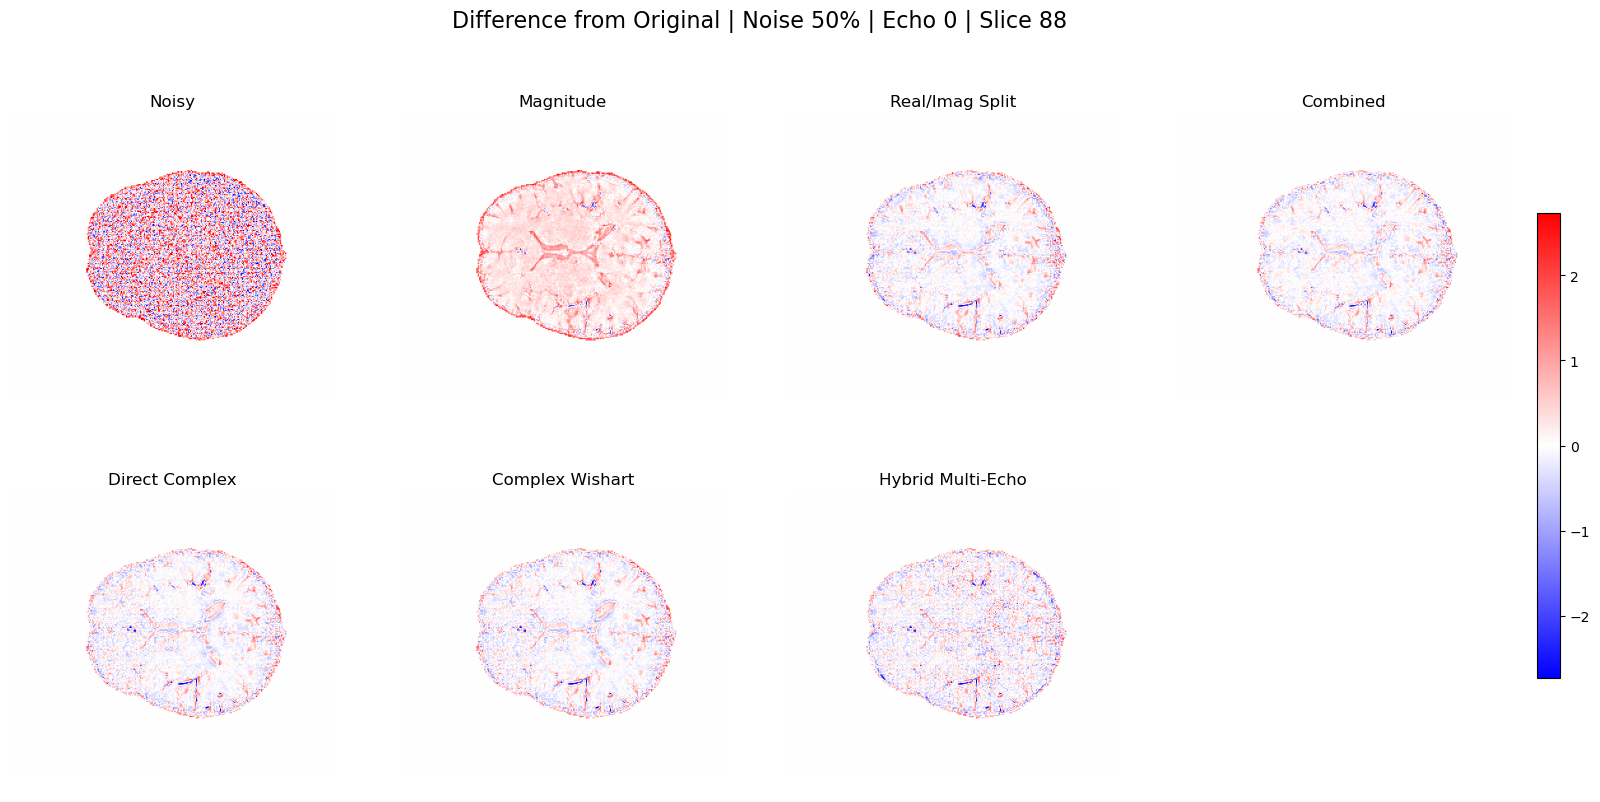

In [31]:
for noise_level in NOISE_LEVELS:

    noisy_mag = load_noisy_magnitude(noise_level)

    methods_vis = {
        "Noisy": noisy_mag,
        "Magnitude": load_magnitude_result(noise_level),
        "Real/Imag Split": load_split_result(noise_level),
        "Combined": load_combined_result(noise_level),
        "Direct Complex": load_direct_complex_result(noise_level),
        "Complex Wishart": load_complex_wishart_result(noise_level),
        "Hybrid Multi-Echo": load_hybrid_result(noise_level),
    }

    ref = orig_mag[
        :,
        :,
        VIS_SLICE,
        VIS_ECHO
    ]

    mask_2d = mask[:, :, VIS_SLICE]

    diff_images = {}

    for name, image in methods_vis.items():
        test = image[
            :,
            :,
            VIS_SLICE,
            VIS_ECHO
        ]

        diff_images[name] = test - ref

    # 모든 방법에 동일한 symmetric display range 적용
    all_abs = np.concatenate([
        np.abs(diff[mask_2d]).ravel()
        for diff in diff_images.values()
    ])

    diff_limit = np.percentile(
        all_abs,
        99
    )

    fig, axes = plt.subplots(
        2,
        4,
        figsize=(20, 9)
    )

    axes = axes.ravel()

    for ax, (name, diff) in zip(
        axes,
        diff_images.items()
    ):
        im = ax.imshow(
            diff.T,
            cmap="bwr",
            origin="lower",
            vmin=-diff_limit,
            vmax=diff_limit
        )

        ax.set_title(name)
        ax.axis("off")

    for ax in axes[len(diff_images):]:
        ax.axis("off")

    fig.colorbar(
        im,
        ax=axes.tolist(),
        fraction=0.015,
        pad=0.02
    )

    fig.suptitle(
        f"Difference from Original | Noise {noise_level}% | "
        f"Echo {VIS_ECHO} | Slice {VIS_SLICE}",
        fontsize=16
    )

    plt.show()


### 15. 모든 Echo 영상 비교

선택한 Noise Level에서 6개 Echo 전체를 한 번에 비교한다.

행은 denoising 방법, 열은 Echo 0~5를 나타낸다.


Magnitude      : data\denoised\magnitude\denoised_magnitude_30_r2.mat -> deno_mag
Real/Imag Split: data\denoised\real_imag\denoised_real_imag_30_r2.mat -> deno_complex
Combined       : data\denoised\real_imag_combined\denoised_real_imag_combined_30_r2.mat -> deno_complex
Direct Complex : data\denoised\direct_complex\denoised_direct_complex_30_r2.mat -> deno_complex
Complex Wishart : data\denoised\complex_wishart\denoised_complex_wishart_30_r2_a0.99.mat -> denoised_complex
Hybrid MultiEcho: data\denoised\hybrid_multi_echo\denoised_hybrid_multi_echo_30_r2.mat -> denoised_complex


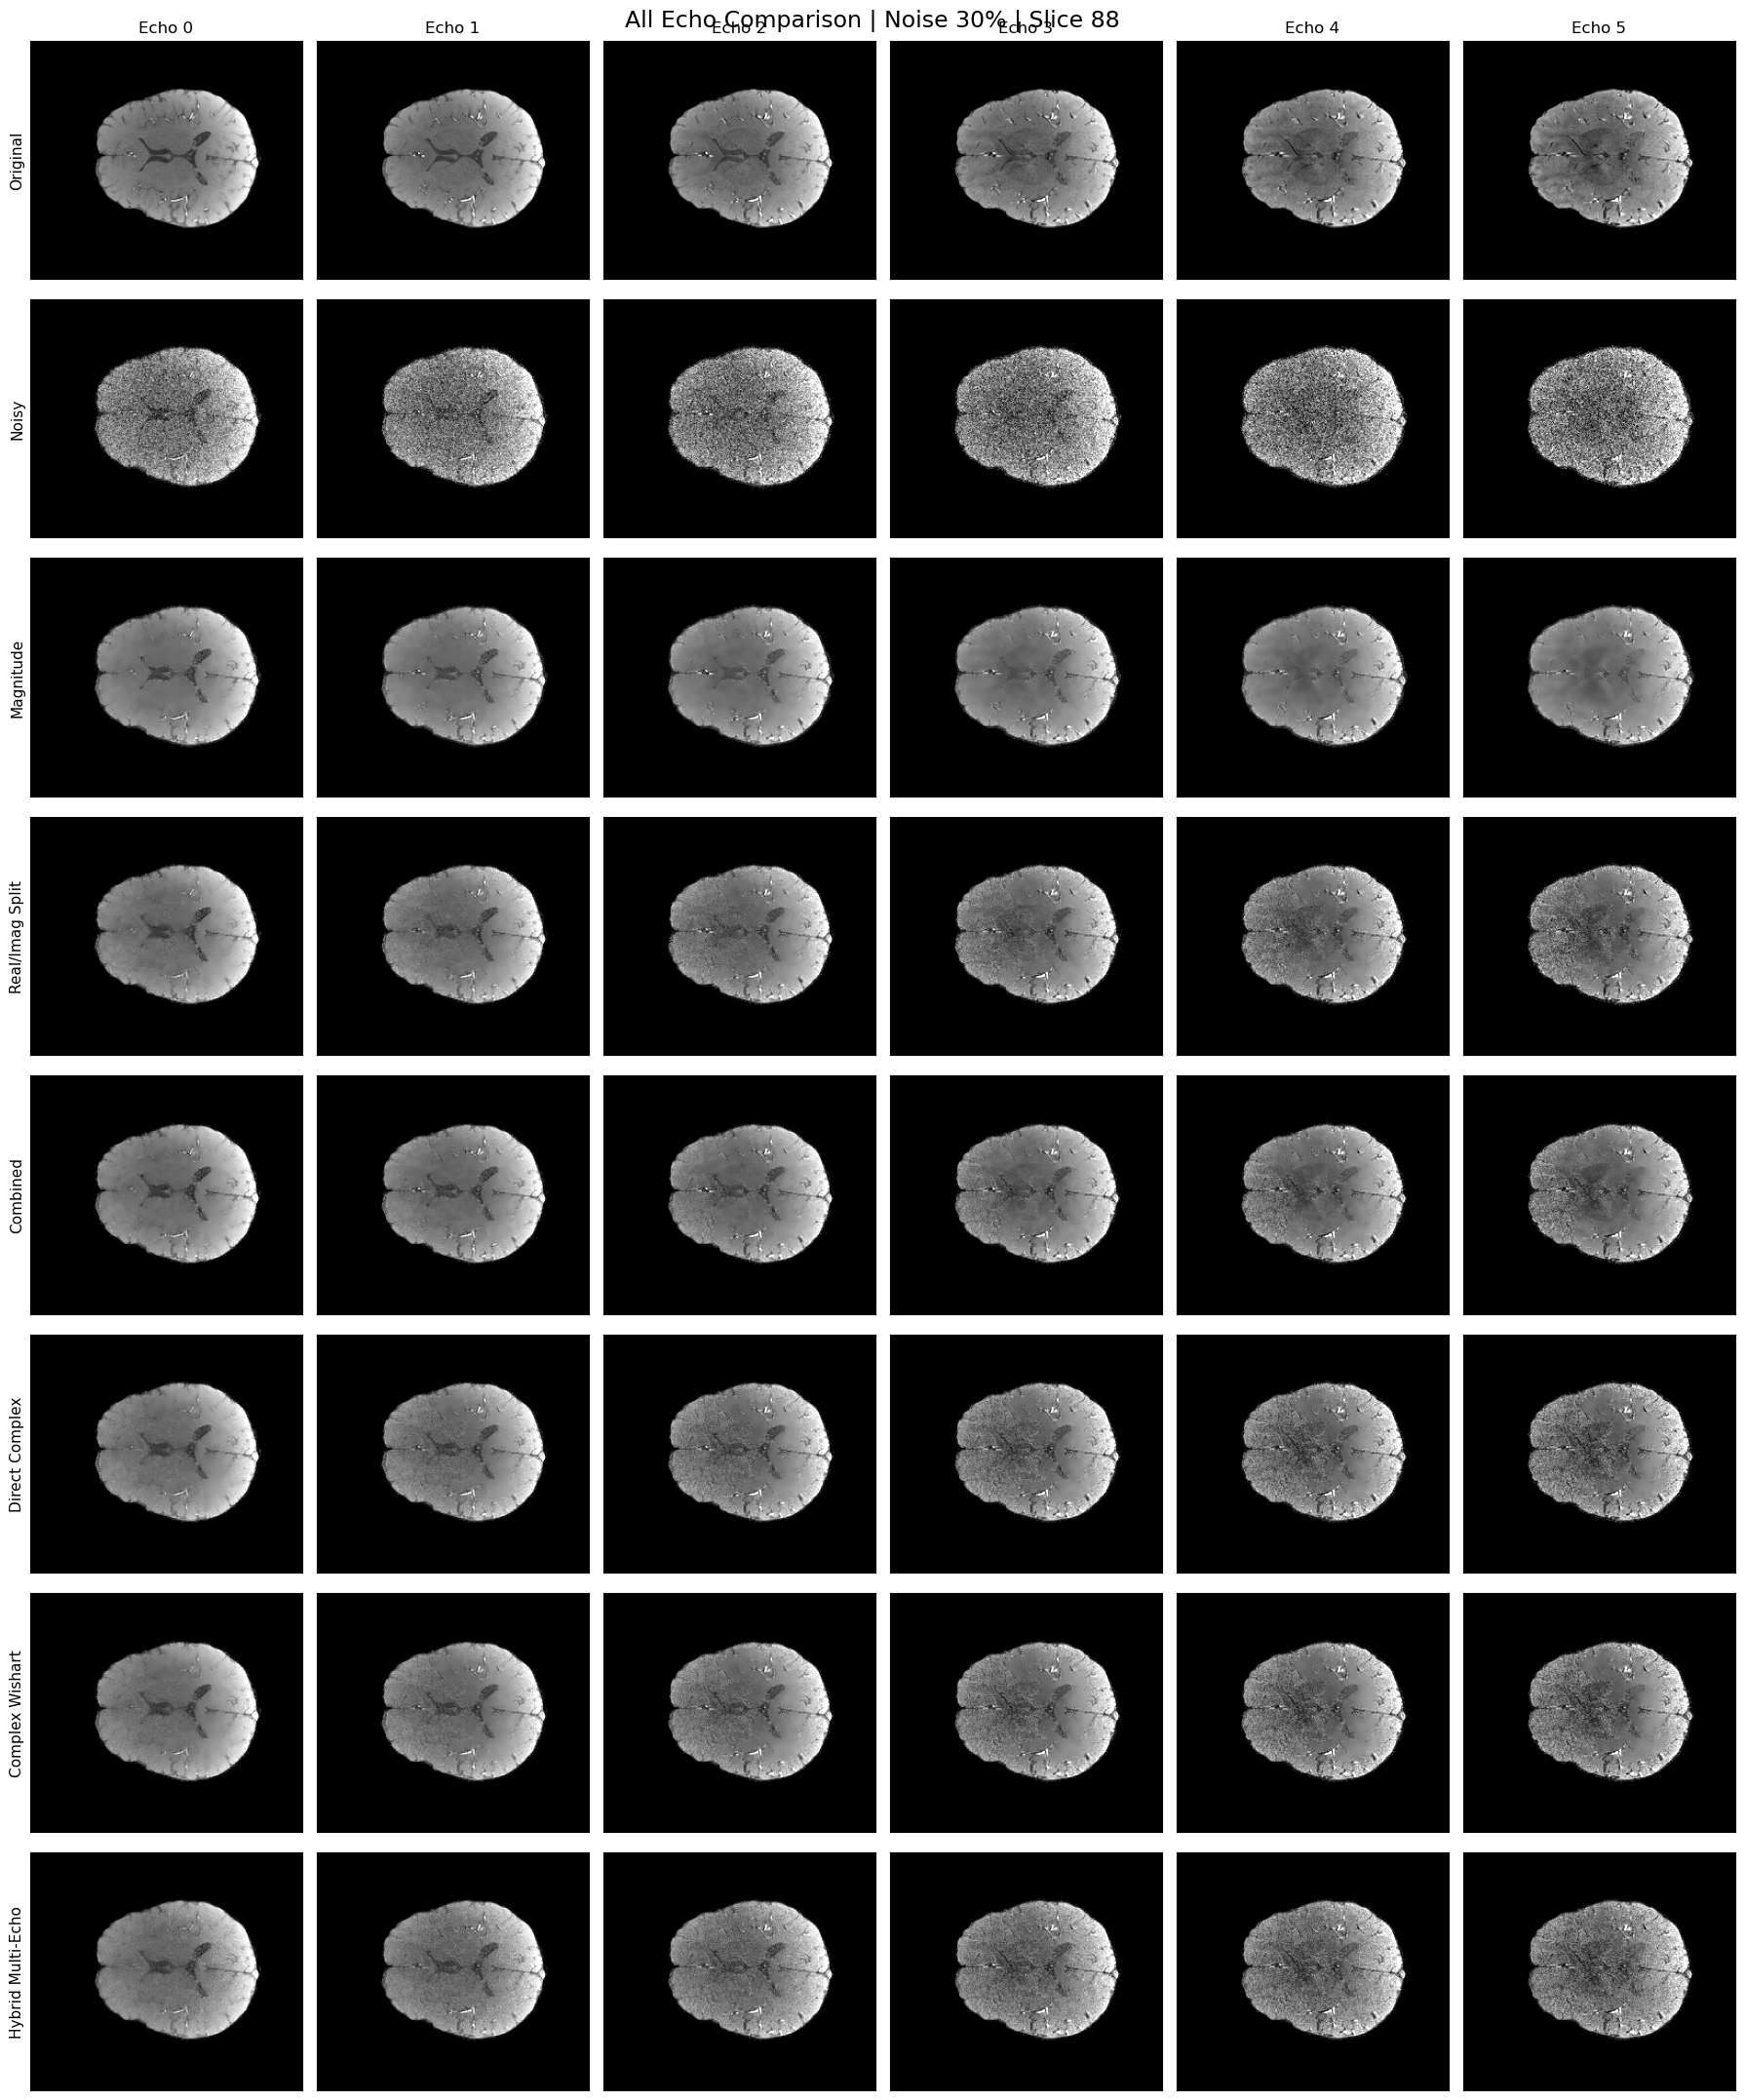

In [33]:
VIS_NOISE = 30

all_methods = {
    "Original": orig_mag,
    "Noisy": load_noisy_magnitude(VIS_NOISE),
    "Magnitude": load_magnitude_result(VIS_NOISE),
    "Real/Imag Split": load_split_result(VIS_NOISE),
    "Combined": load_combined_result(VIS_NOISE),
    "Direct Complex": load_direct_complex_result(VIS_NOISE),
    "Complex Wishart": load_complex_wishart_result(VIS_NOISE),
    "Hybrid Multi-Echo": load_hybrid_result(VIS_NOISE),
}

fig, axes = plt.subplots(
    len(all_methods),
    N_ECHO,
    figsize=(18, 22)
)

for row, (method, image) in enumerate(
    all_methods.items()
):
    for echo in range(N_ECHO):

        ref_echo = orig_mag[
            :,
            :,
            VIS_SLICE,
            echo
        ]

        mask_2d = mask[:, :, VIS_SLICE]

        evmin = np.percentile(
            ref_echo[mask_2d],
            1
        )

        evmax = np.percentile(
            ref_echo[mask_2d],
            99
        )

        img = image[
            :,
            :,
            VIS_SLICE,
            echo
        ]

        axes[row, echo].imshow(
            img.T,
            cmap="gray",
            origin="lower",
            vmin=evmin,
            vmax=evmax
        )

        if row == 0:
            axes[row, echo].set_title(
                f"Echo {echo}"
            )

        if echo == 0:
            axes[row, echo].set_ylabel(
                method,
                fontsize=11
            )

        axes[row, echo].set_xticks([])
        axes[row, echo].set_yticks([])

fig.suptitle(
    f"All Echo Comparison | Noise {VIS_NOISE}% | Slice {VIS_SLICE}",
    fontsize=17
)

plt.tight_layout()
plt.show()


### 16. RSNR Heatmap

Noise level × Echo 조합별 RSNR을 방법별 heatmap으로 확인한다.


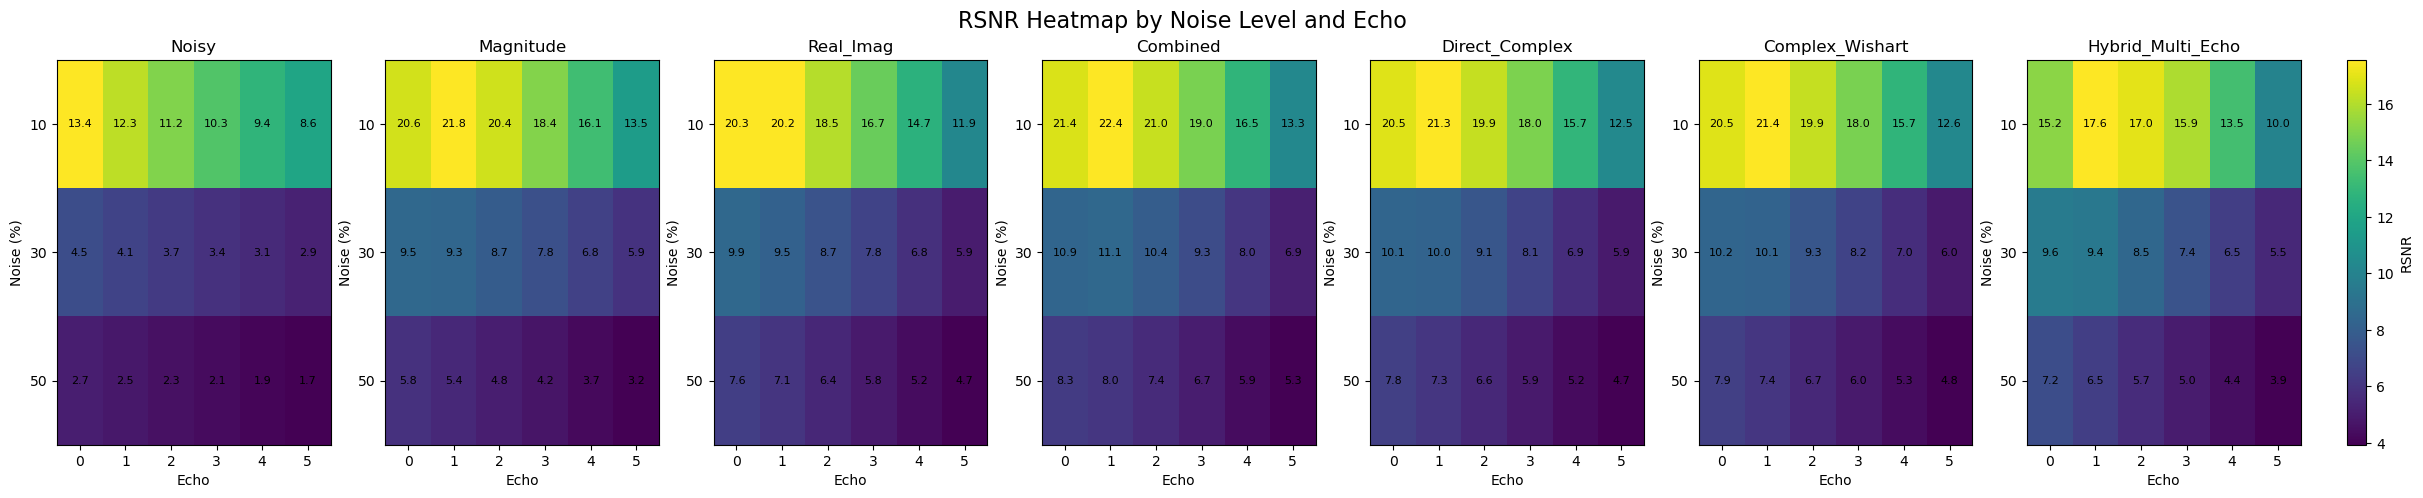

In [35]:
methods_heatmap = [
    "Noisy",
    "Magnitude",
    "Real_Imag",
    "Combined",
    "Direct_Complex",
    "Complex_Wishart",
    "Hybrid_Multi_Echo"
]

fig, axes = plt.subplots(
    1,
    len(methods_heatmap),
    figsize=(30, 5)
)

for ax, method in zip(
    axes,
    methods_heatmap
):

    temp = (
        df_rsnr[
            df_rsnr["Method"] == method
        ]
        .pivot(
            index="Noise",
            columns="Echo",
            values="RSNR"
        )
        .sort_index()
    )

    im = ax.imshow(
        temp.values,
        aspect="auto"
    )

    ax.set_title(method)
    ax.set_xlabel("Echo")
    ax.set_ylabel("Noise (%)")

    ax.set_xticks(
        range(len(temp.columns))
    )

    ax.set_xticklabels(
        temp.columns
    )

    ax.set_yticks(
        range(len(temp.index))
    )

    ax.set_yticklabels(
        temp.index
    )

    for i in range(temp.shape[0]):
        for j in range(temp.shape[1]):
            ax.text(
                j,
                i,
                f"{temp.iloc[i, j]:.1f}",
                ha="center",
                va="center",
                fontsize=8
            )

fig.colorbar(
    im,
    ax=axes.tolist(),
    fraction=0.015,
    pad=0.02,
    label="RSNR"
)

fig.suptitle(
    "RSNR Heatmap by Noise Level and Echo",
    fontsize=16
)

plt.show()


### 17. 방법별 평균 RSNR 순위


In [37]:
ranking = (
    mean_rsnr
    .sort_values(
        ["Noise", "RSNR"],
        ascending=[True, False]
    )
    .copy()
)

ranking["Rank"] = (
    ranking
    .groupby("Noise")["RSNR"]
    .rank(
        method="dense",
        ascending=False
    )
    .astype(int)
)

ranking = ranking[
    ["Noise", "Rank", "Method", "RSNR"]
]

ranking


,Noise,Rank,Method,RSNR
0,10,1,Combined,18.917491
4,10,2,Magnitude,18.465621
1,10,3,Complex_Wishart,18.002506
2,10,4,Direct_Complex,17.987486
6,10,5,Real_Imag,17.040161
3,10,6,Hybrid_Multi_Echo,14.869446
5,10,7,Noisy,10.864842
7,30,1,Combined,9.415072
8,30,2,Complex_Wishart,8.453714
9,30,3,Direct_Complex,8.354044


### 18. 결과 저장


In [39]:
OUT_DIR = DATA_DIR / "evaluation"
OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

df_rsnr.to_csv(
    OUT_DIR / "RSNR_all_results.csv",
    index=False
)

rsnr_table.to_csv(
    OUT_DIR / "RSNR_echo_comparison.csv"
)

mean_rsnr_table.to_csv(
    OUT_DIR / "RSNR_mean_comparison.csv"
)

improvement_table.to_csv(
    OUT_DIR / "RSNR_improvement_percent.csv"
)

ranking.to_csv(
    OUT_DIR / "RSNR_ranking.csv",
    index=False
)

print("저장 완료:", OUT_DIR)


저장 완료: data\evaluation
